# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Irzam Hafis Fabiansyah | 5054251024 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
FEATURES = ["Annual Income (k$)", "Spending Score (1-100)"]

In [2]:
df = pd.read_csv("Mall_Customers.csv")

display(df.head())
print("Jumlah baris/kolom:", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\nStatistik deskriptif:")
display(df.describe())
print("Missing value per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("Jumlah CustomerID duplikat:", df["CustomerID"].duplicated().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Jumlah baris/kolom: (200, 5)

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik deskriptif:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0
Jumlah CustomerID duplikat: 0


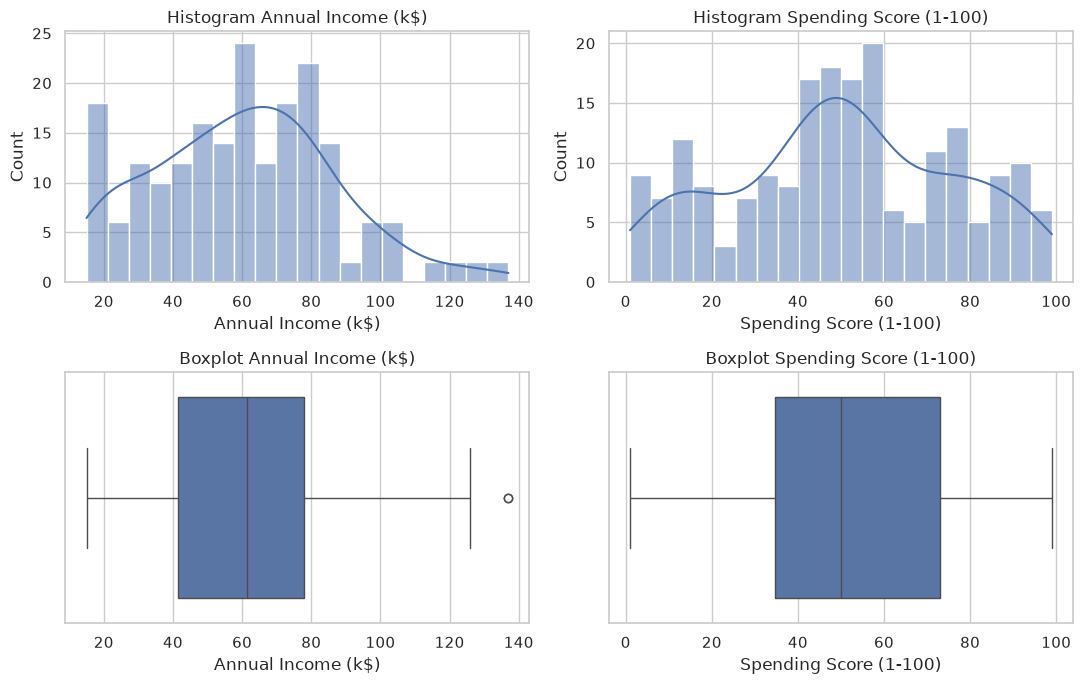

Annual Income (k$): 2 outlier (IQR), rentang 15-137
Spending Score (1-100): 0 outlier (IQR), rentang 1-99


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, col in enumerate(FEATURES):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Histogram {col}")
    sns.boxplot(x=df[col], ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot {col}")
plt.tight_layout()
plt.show()

# Deteksi outlier sederhana dengan aturan IQR
for col in FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(f"{col}: {len(out)} outlier (IQR), rentang {df[col].min()}-{df[col].max()}")

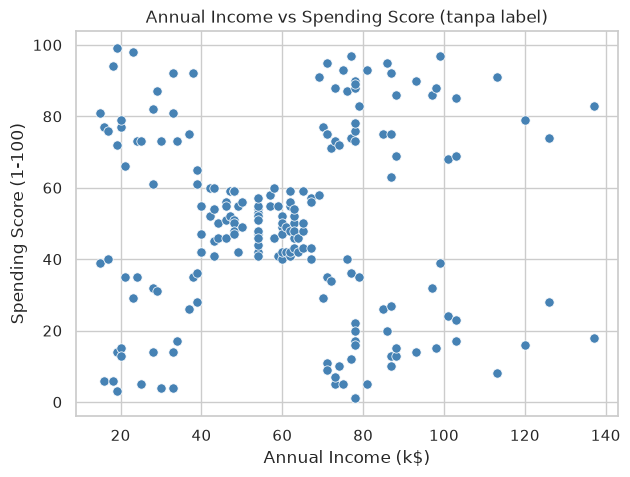

In [4]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x=FEATURES[0], y=FEATURES[1], color="steelblue", s=45)
plt.title("Annual Income vs Spending Score (tanpa label)")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**
- Tidak ada missing value dan tidak ada baris duplikat. Semua 200 baris lengkap, jadi tidak ada data yang perlu dibuang.
- Annual Income berkisar 15–137 k$ (rata-rata 60,6; median 61,5), sedangkan Spending Score berkisar 1–99 (rata-rata 50,2; median 50). Spending Score sebarannya cukup merata dan tidak punya outlier. Income agak miring ke kanan dengan 2 outlier menurut aturan IQR, yaitu pelanggan dengan pendapatan sekitar 137 k$.
- Di scatter plot terlihat beberapa kelompok yang cukup jelas: satu kelompok besar di tengah, dua kelompok di income rendah (satu spending tinggi, satu spending rendah), dan dua kelompok di income tinggi (juga spending tinggi dan rendah). Jadi kira-kira ada 5 kelompok, walaupun batas kelompok tengah dengan kelompok di sekitarnya tidak terlalu tegas.

# 2. Preprocessing

In [5]:
print("Missing value:", df[FEATURES].isna().sum().sum())
print("Baris duplikat pada fitur + atribut lain:", df.drop(columns="CustomerID").duplicated().sum())

# Tidak ada missing value maupun duplikat, tetapi tetap dijaga agar kode reusable.
df = df.dropna(subset=FEATURES).drop_duplicates(subset=[c for c in df.columns if c != "CustomerID"]).reset_index(drop=True)

X = df[FEATURES].copy()
print("Bentuk X:", X.shape)
X.head()

Missing value: 0
Baris duplikat pada fitur + atribut lain: 0
Bentuk X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

display(X_scaled.head())
display(X_scaled.describe().round(3))

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


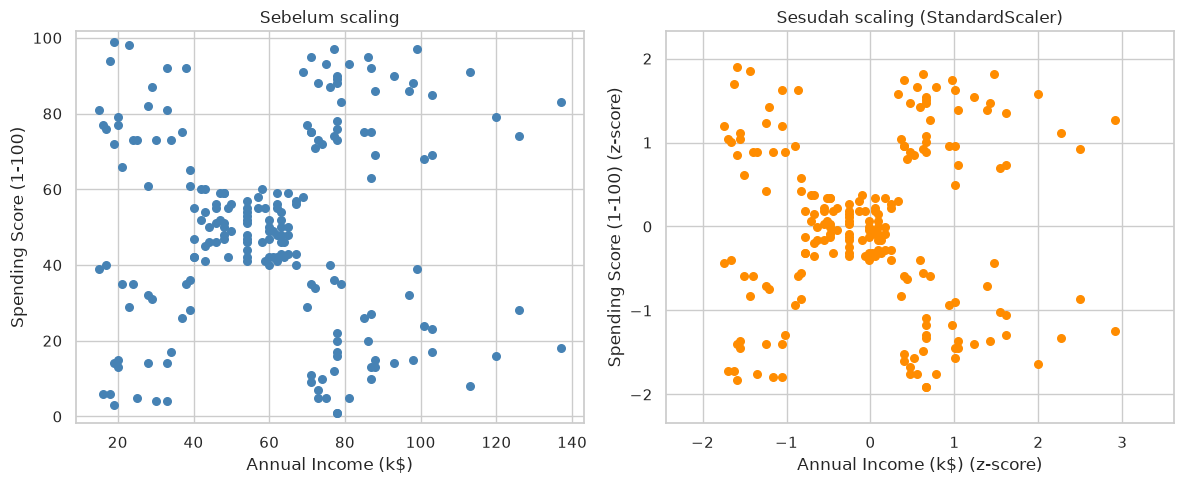

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], s=30, color="steelblue")
axes[0].set_title("Sebelum scaling")
axes[0].set_xlabel(X.columns[0]); axes[0].set_ylabel(X.columns[1])
axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], s=30, color="darkorange")
axes[1].set_title("Sesudah scaling (StandardScaler)")
axes[1].set_xlabel(X_scaled.columns[0] + " (z-score)"); axes[1].set_ylabel(X_scaled.columns[1] + " (z-score)")
for ax in axes: ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Alasan pemilihan fitur:** Annual Income dan Spending Score paling langsung menggambarkan kemampuan dan kebiasaan belanja pelanggan, jadi cocok untuk segmentasi. Dengan dua fitur saja, hasilnya juga bisa digambar di bidang 2D dan mudah dibaca.

**Kenapa CustomerID tidak dipakai:** kolom ini hanya nomor urut pelanggan dan tidak menyimpan informasi perilaku apa pun. Kalau ikut dimasukkan, jarak antar titik akan dipengaruhi nomor urut yang tidak bermakna, dan cluster yang terbentuk jadi tidak masuk akal.

**Kenapa scaling perlu:** DBSCAN dan BIRCH bekerja dengan jarak, sedangkan GMM bergantung pada kovarians, jadi fitur dengan skala lebih besar akan lebih mendominasi. Pada data ini rentang income (15–137) dan spending (1–99) memang berbeda, walaupun standar deviasinya mirip (sekitar 26). Setelah `StandardScaler`, kedua fitur punya rata-rata 0 dan standar deviasi 1 (lihat tabel `describe()`), sehingga `eps` dan `threshold` berlaku sama untuk kedua sumbu. Plot sebelum dan sesudah scaling juga menunjukkan bentuk sebaran tidak berubah, hanya skala sumbunya.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [9]:
def count_clusters(labels):
    return len(set(labels)) - (1 if -1 in labels else 0), int((np.asarray(labels) == -1).sum())

print("Anggota per label:")
print(pd.Series(labels_dbscan).value_counts().sort_index().rename("jumlah"))
n_cl, n_noise = count_clusters(labels_dbscan)
print(f"\nJumlah cluster (tanpa noise): {n_cl}")
print(f"Jumlah noise (label -1)     : {n_noise} ({n_noise / len(X):.1%})")

Anggota per label:
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: jumlah, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah noise (label -1)     : 35 (17.5%)


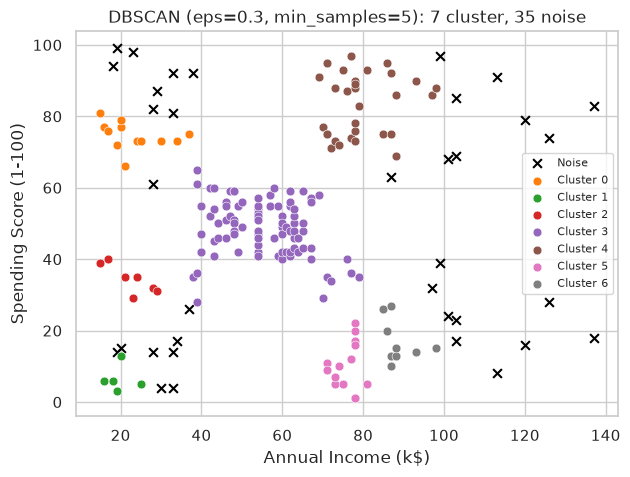

In [10]:
def plot_clusters(ax, data, labels, title):
    labels = np.asarray(labels)
    palette = sns.color_palette("tab10", n_colors=max(len(set(labels)), 2))
    for i, lab in enumerate(sorted(set(labels))):
        m = labels == lab
        if lab == -1:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], c="black", marker="x", s=40, label="Noise")
        else:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], color=palette[i % 10], s=40, edgecolor="white", linewidth=0.4, label=f"Cluster {lab}")
    ax.set_title(title)
    ax.set_xlabel(data.columns[0]); ax.set_ylabel(data.columns[1])
    ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_dbscan, f"DBSCAN (eps=0.3, min_samples=5): {n_cl} cluster, {n_noise} noise")
plt.show()

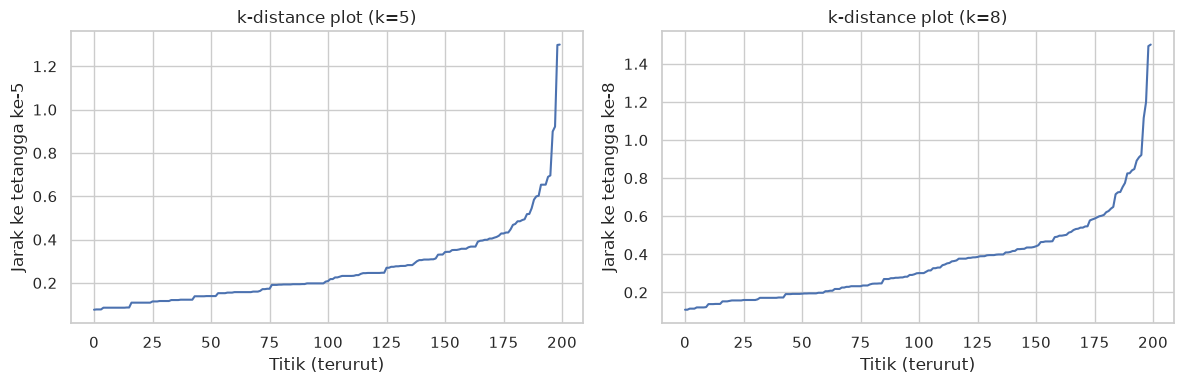

,eps,min_samples,n_cluster,n_noise,silhouette
0,0.2,3,13,44,0.470
1,0.2,5,7,77,0.586
2,0.2,8,2,116,0.603
3,0.2,10,1,129,NaN
4,0.3,3,9,14,0.472
5,0.3,5,7,35,0.524
6,0.3,8,5,72,0.593
7,0.3,10,4,88,0.607
8,0.4,3,4,10,0.395
9,0.4,5,4,15,0.478


min_samples,3,5,8,10
n_cluster,,,,
0.2,13,7,2,1
0.3,9,7,5,4
0.4,4,4,5,4
0.5,2,2,2,4
0.6,1,1,1,1


min_samples,3,5,8,10
n_noise,,,,
0.2,44,77,116,129
0.3,14,35,72,88
0.4,10,15,25,51
0.5,7,8,15,21
0.6,0,5,6,10


DBSCAN terpilih (eps=0.4, min_samples=8): 5 cluster, 25 noise


In [11]:
# k-distance plot sebagai panduan memilih eps
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, [5, 8]):
    dist, _ = NearestNeighbors(n_neighbors=k).fit(X_scaled).kneighbors(X_scaled)
    ax.plot(np.sort(dist[:, -1]))
    ax.set_title(f"k-distance plot (k={k})")
    ax.set_xlabel("Titik (terurut)"); ax.set_ylabel(f"Jarak ke tetangga ke-{k}")
plt.tight_layout()
plt.show()

rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k, n = count_clusters(lab)
        mask = lab != -1
        sil = silhouette_score(X_scaled[mask], lab[mask]) if k >= 2 else np.nan
        rows.append({"eps": eps, "min_samples": ms, "n_cluster": k, "n_noise": n, "silhouette": sil})
dbscan_grid = pd.DataFrame(rows)
display(dbscan_grid.round(3))
display(dbscan_grid.pivot(index="eps", columns="min_samples", values="n_cluster").rename_axis("n_cluster"))
display(dbscan_grid.pivot(index="eps", columns="min_samples", values="n_noise").rename_axis("n_noise"))

# Parameter terpilih: menghasilkan 5 cluster dengan noise relatif sedikit
dbscan_best = DBSCAN(eps=0.4, min_samples=8)
labels_dbscan_best = dbscan_best.fit_predict(X_scaled)
k, n = count_clusters(labels_dbscan_best)
print(f"DBSCAN terpilih (eps=0.4, min_samples=8): {k} cluster, {n} noise")

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban (dari tabel eksperimen di atas):**
- **Pengaruh `eps`.** Makin besar `eps`, makin banyak tetangga yang terjangkau, sehingga noise berkurang dan cluster mulai menyatu. Pada `min_samples=5`, noise turun dari 77 ke 5 saat `eps` naik dari 0,2 ke 0,6, sementara jumlah cluster turun dari 7 sampai tinggal 1.
- **Pengaruh `min_samples`.** Makin besar nilainya, syarat untuk menjadi titik inti makin ketat, jadi noise bertambah dan cluster kecil hilang. Pada `eps=0,3`, noise naik dari 14 ke 88 ketika `min_samples` dinaikkan dari 3 ke 10, dan jumlah cluster turun dari 9 ke 4.
- **Kombinasi yang bermasalah.** `eps=0,6` selalu menghasilkan satu cluster besar, apa pun `min_samples`-nya. Di sisi lain, `eps=0,2` dengan `min_samples=10` hanya menghasilkan satu cluster dan 129 titik noise (lebih dari separuh data). `eps=0,2` dengan `min_samples` 5 atau 8 juga terlalu banyak noise (77 dan 116).
- **Soal silhouette.** Silhouette tertinggi (sekitar 0,60) justru muncul pada kombinasi yang membuang banyak titik sebagai noise atau hanya menyisakan 2–4 cluster, karena yang dinilai hanya inti yang padat. Jadi angka ini tidak bisa dibaca sendirian. Saya memilih `eps=0,4` dan `min_samples=8`: hasilnya 5 cluster yang cocok dengan pola di scatter plot, noise 25 titik (12,5%), dan silhouette 0,549.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Jumlah subcluster (leaf):", len(birch.subcluster_centers_))

Jumlah subcluster (leaf): 10


In [13]:
print(pd.Series(labels_birch).value_counts().sort_index().rename("jumlah"))
print("Jumlah cluster:", len(set(labels_birch)))

0     36
1    109
2      8
3     25
4     22
Name: jumlah, dtype: int64
Jumlah cluster: 5


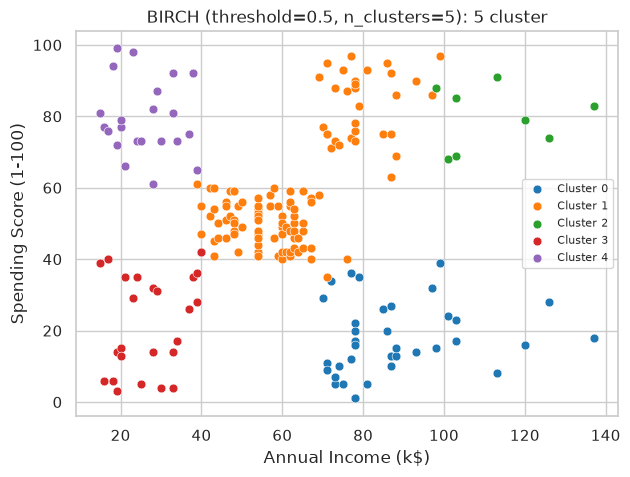

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_birch, f"BIRCH (threshold=0.5, n_clusters=5): {len(set(labels_birch))} cluster")
plt.show()

In [15]:
rows = []
for t in [0.3, 0.5, 0.7, 1.0]:
    for nc in [5, None]:
        m = Birch(threshold=t, n_clusters=nc).fit(X_scaled)
        lab = m.labels_
        k = len(set(lab))
        rows.append({"threshold": t, "n_clusters (param)": nc if nc else "None",
                     "n_subcluster": len(m.subcluster_centers_), "n_cluster akhir": k,
                     "silhouette": silhouette_score(X_scaled, lab) if k >= 2 else np.nan})
birch_grid = pd.DataFrame(rows)
display(birch_grid.round(3))

# Threshold terbaik (n_clusters=5) berdasarkan silhouette, hanya yang benar-benar menghasilkan 5 cluster
cand = birch_grid[(birch_grid["n_clusters (param)"] == 5) & (birch_grid["n_cluster akhir"] == 5)]
best_t = cand.loc[cand["silhouette"].idxmax(), "threshold"]
birch_best = Birch(threshold=best_t, n_clusters=5).fit(X_scaled)
labels_birch_best = birch_best.labels_
print("Threshold BIRCH terpilih:", best_t)

,threshold,n_clusters (param),n_subcluster,n_cluster akhir,silhouette
0,0.3,5,23,5,0.478
1,0.3,None,23,23,0.414
2,0.5,5,10,5,0.414
3,0.5,None,10,10,0.477
4,0.7,5,6,5,0.421
5,0.7,None,6,6,0.486
6,1.0,5,4,4,0.389
7,1.0,None,4,4,0.389


Threshold BIRCH terpilih: 0.3


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**
- **Pengaruh `threshold`.** Semakin besar `threshold`, semakin sedikit subcluster yang terbentuk karena titik yang agak jauh pun boleh digabung: 23, 10, 6, dan 4 subcluster untuk threshold 0,3; 0,5; 0,7; dan 1,0. Pada `threshold=1,0` subcluster-nya hanya 4, jadi permintaan `n_clusters=5` tidak bisa dipenuhi dan hasil akhirnya hanya 4 cluster (sklearn juga memberi peringatan). Untuk `n_clusters=5`, silhouette terbaik didapat dari threshold terkecil (0,478 pada 0,3, dibanding 0,414 pada 0,5 dan 0,421 pada 0,7), jadi itu yang saya pakai untuk perbandingan akhir.
- **BIRCH vs DBSCAN untuk titik yang jauh.** DBSCAN menandai titik yang tidak cukup padat sebagai noise (-1) sehingga cluster utama tidak terganggu. BIRCH tidak punya konsep noise, jadi semua titik harus masuk ke suatu cluster. Hasilnya terlihat di profil BIRCH: tiga pelanggan berpendapatan sangat tinggi (median 126 k$) dijadikan satu cluster kecil sendiri, sedangkan DBSCAN memasukkan titik-titik seperti itu ke noise.
- **Pengaruh `n_clusters`.** Ya, hasilnya berubah. Kalau `n_clusters` diisi, BIRCH menggabungkan subcluster-nya lagi sampai jumlah cluster sesuai target (5), walaupun subcluster awalnya 23 atau 10. Kalau `None`, hasilnya langsung berupa subcluster, misalnya 23 cluster pada threshold 0,3, yang terlalu rinci untuk segmentasi pelanggan.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42, n_init=10)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)
print("Konvergen:", gmm.converged_, "| iterasi EM:", gmm.n_iter_)
print("Bobot komponen:", gmm.weights_.round(3))

Konvergen: True | iterasi EM: 5
Bobot komponen: [0.413 0.197 0.104 0.166 0.121]


In [17]:
print(pd.Series(labels_gmm).value_counts().sort_index().rename("jumlah"))

proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f"P(c{i})" for i in range(proba.shape[1])]).round(3)
display(proba_df.head(10))

max_p = proba.max(axis=1)
uncertain = max_p < 0.9
print(f"Probabilitas maksimum: min={max_p.min():.3f}, rata-rata={max_p.mean():.3f}")
print(f"Titik dengan keanggotaan tidak pasti (max proba < 0.9): {uncertain.sum()}")
display(pd.concat([X[uncertain], proba_df[uncertain]], axis=1).head(10))

0    84
1    39
2    21
3    33
4    23
Name: jumlah, dtype: int64


,P(c0),P(c1),P(c2),P(c3),P(c4)
0,0.000,0.0,0.001,0.0,0.999
1,0.000,0.0,1.000,0.0,0.000
2,0.000,0.0,0.000,0.0,1.000
3,0.000,0.0,1.000,0.0,0.000
4,0.000,0.0,0.002,0.0,0.998
5,0.000,0.0,1.000,0.0,0.000
6,0.000,0.0,0.000,0.0,1.000
7,0.000,0.0,1.000,0.0,0.000
8,0.000,0.0,0.000,0.0,1.000
9,0.001,0.0,0.998,0.0,0.000


Probabilitas maksimum: min=0.503, rata-rata=0.983
Titik dengan keanggotaan tidak pasti (max proba < 0.9): 8


,Annual Income (k$),Spending Score (1-100),P(c0),P(c1),P(c2),P(c3),P(c4)
27,28,61,0.279,0.000,0.675,0.000,0.046
45,39,65,0.822,0.007,0.157,0.000,0.014
47,40,47,0.891,0.000,0.001,0.000,0.108
48,40,42,0.611,0.000,0.000,0.000,0.388
49,40,42,0.611,0.000,0.000,0.000,0.388
55,43,41,0.796,0.000,0.000,0.000,0.204
124,70,29,0.497,0.000,0.000,0.503,0.000
160,79,35,0.772,0.000,0.000,0.228,0.000


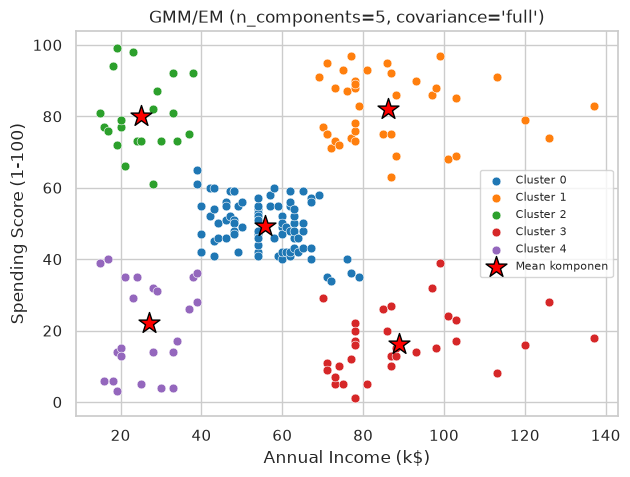

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(ax, X, labels_gmm, "GMM/EM (n_components=5, covariance='full')")
ax.scatter(*scaler.inverse_transform(gmm.means_).T, c="red", marker="*", s=250, edgecolor="black", label="Mean komponen")
ax.legend(fontsize=8)
plt.show()

,n_components,silhouette,BIC,AIC
0,2,0.387,1148.473,1112.191
1,3,0.347,1116.501,1060.430
2,4,0.451,1079.494,1003.633
3,5,0.554,1058.652,963.001
4,6,0.536,1071.567,956.126
5,7,0.385,1085.590,950.359
6,8,0.465,1082.480,927.459


Silhouette tertinggi di k = 5
BIC terendah di k         = 5


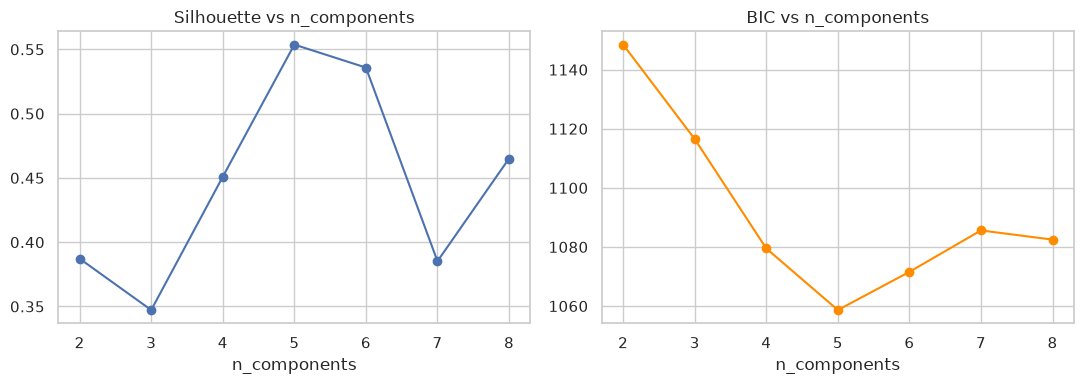

In [19]:
rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=42, n_init=10).fit(X_scaled)
    lab = g.predict(X_scaled)
    rows.append({"n_components": k, "silhouette": silhouette_score(X_scaled, lab), "BIC": g.bic(X_scaled), "AIC": g.aic(X_scaled)})
gmm_grid = pd.DataFrame(rows)
display(gmm_grid.round(3))
print("Silhouette tertinggi di k =", gmm_grid.loc[gmm_grid["silhouette"].idxmax(), "n_components"])
print("BIC terendah di k         =", gmm_grid.loc[gmm_grid["BIC"].idxmin(), "n_components"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(gmm_grid["n_components"], gmm_grid["silhouette"], marker="o"); axes[0].set_title("Silhouette vs n_components")
axes[1].plot(gmm_grid["n_components"], gmm_grid["BIC"], marker="o", color="darkorange"); axes[1].set_title("BIC vs n_components")
for ax in axes: ax.set_xlabel("n_components")
plt.tight_layout()
plt.show()

best_k = int(gmm_grid.loc[gmm_grid["BIC"].idxmin(), "n_components"])
gmm_best = GaussianMixture(n_components=best_k, covariance_type="full", random_state=42, n_init=10).fit(X_scaled)
labels_gmm_best = gmm_best.predict(X_scaled)

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban:**
- **Arti probabilitas keanggotaan.** `predict_proba` memberi peluang sebuah titik berasal dari tiap komponen Gaussian. Jumlahnya per titik selalu 1, dan label cluster diambil dari komponen dengan peluang terbesar. Kebanyakan titik hampir pasti masuk satu komponen (rata-rata peluang maksimum 0,983), tetapi ada 8 titik yang kurang pasti (peluang maksimum di bawah 0,9). Yang paling ragu adalah pelanggan dengan income 70 k$ dan spending 29, dengan peluang 0,497 dan 0,503 untuk dua komponen berbeda. Titik seperti ini terletak di perbatasan antar-cluster, dan informasi itu tidak terlihat pada hard clustering.
- **Ketika `n_components` diubah.** Dengan 2 komponen, kelompok yang berbeda tergabung (silhouette 0,387). Dengan 6–8 komponen, kelompok alami mulai terpecah-pecah dan skornya turun lagi (0,385–0,536). Pada 5 komponen hasilnya paling cocok dengan pola di scatter plot.
- **Kenapa jumlah cluster harus ditentukan dulu.** GMM adalah model parametrik: jumlah komponen menentukan banyaknya parameter (bobot, mean, kovarians) yang diestimasi EM, jadi harus tetap sejak awal. Karena itu, memilih jumlahnya dibantu BIC dan silhouette, tidak ditemukan otomatis seperti pada DBSCAN.
- **Silhouette tertinggi vs BIC terendah.** Pada eksperimen ini keduanya sama-sama menunjuk k = 5 (silhouette 0,554 dan BIC 1058,65). Itu kebetulan yang menyenangkan, karena keduanya mengukur hal berbeda: BIC menilai kecocokan model dengan penalti kerumitan, sedangkan silhouette menilai seberapa terpisah cluster-nya. AIC malah terus turun sampai k = 8, jadi cenderung memilih model yang terlalu rumit.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
def evaluate_clustering(X_eval, labels, name, exclude_noise=False):
    labels = np.asarray(labels)
    n_noise = int((labels == -1).sum())
    X_arr = np.asarray(X_eval)
    if exclude_noise:
        mask = labels != -1
        X_arr, labels_eval = X_arr[mask], labels[mask]
    else:
        labels_eval = labels
    n_cluster = len(set(labels_eval))
    res = {"model": name, "n_cluster": n_cluster, "n_noise": n_noise if exclude_noise else "N/A",
           "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    if 2 <= n_cluster < len(labels_eval):
        res["silhouette"] = silhouette_score(X_arr, labels_eval)
        res["davies_bouldin"] = davies_bouldin_score(X_arr, labels_eval)
        res["calinski_harabasz"] = calinski_harabasz_score(X_arr, labels_eval)
    return res

In [21]:
results = pd.DataFrame([
    evaluate_clustering(X_scaled, labels_dbscan_best, "DBSCAN (eps=0.4, min_samples=8)", exclude_noise=True),
    evaluate_clustering(X_scaled, labels_birch_best, f"BIRCH (threshold={best_t}, n_clusters=5)"),
    evaluate_clustering(X_scaled, labels_gmm_best, f"GMM (n_components={best_k}, full)"),
]).set_index("model")
display(results.round(3))

,n_cluster,n_noise,silhouette,davies_bouldin,calinski_harabasz
model,,,,,
"DBSCAN (eps=0.4, min_samples=8)",5,25,0.549,0.501,222.065
"BIRCH (threshold=0.3, n_clusters=5)",5,N/A,0.478,0.648,144.013
"GMM (n_components=5, full)",5,N/A,0.554,0.576,244.940


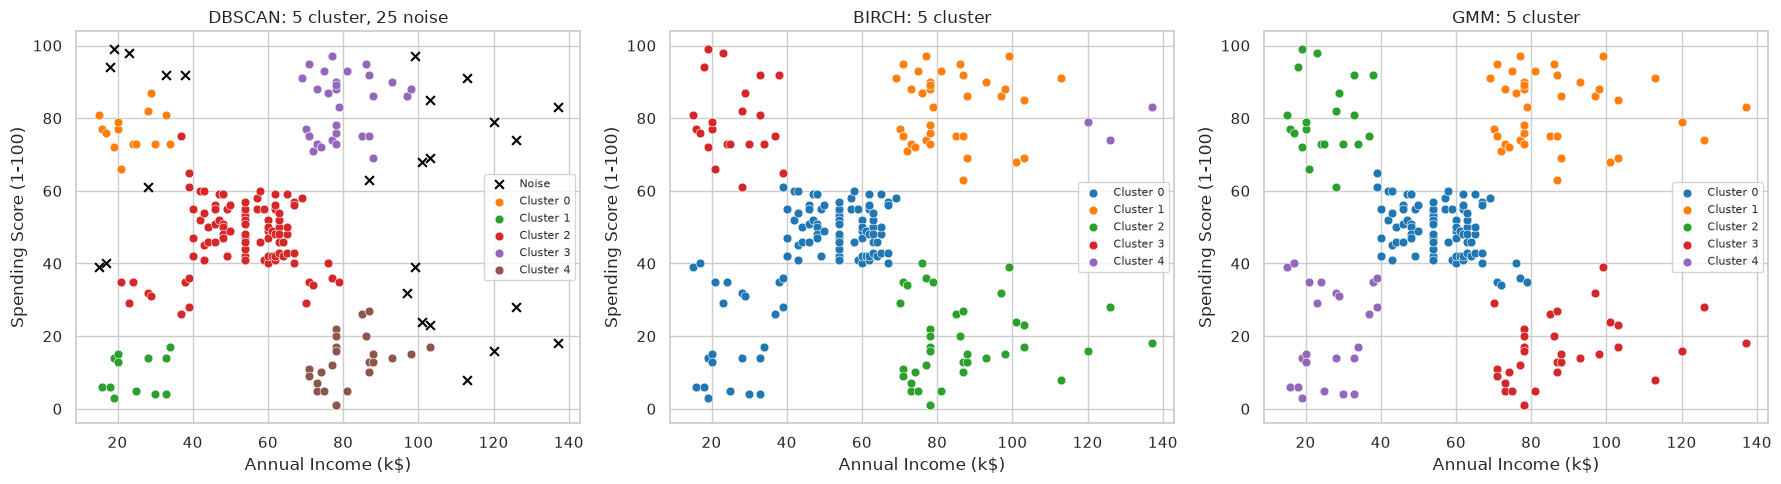

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
k, n = count_clusters(labels_dbscan_best)
plot_clusters(axes[0], X, labels_dbscan_best, f"DBSCAN: {k} cluster, {n} noise")
plot_clusters(axes[1], X, labels_birch_best, f"BIRCH: {len(set(labels_birch_best))} cluster")
plot_clusters(axes[2], X, labels_gmm_best, f"GMM: {len(set(labels_gmm_best))} cluster")
plt.tight_layout()
plt.show()

In [23]:
def profile(labels, name):
    d = X.copy(); d["cluster"] = np.asarray(labels)
    out = d.groupby("cluster").agg(
        jumlah=(FEATURES[0], "size"),
        income_median=(FEATURES[0], "median"), income_mean=(FEATURES[0], "mean"),
        spending_median=(FEATURES[1], "median"), spending_mean=(FEATURES[1], "mean"),
    ).round(1)
    print(f"=== Profil {name} ===" + ("  (cluster -1 = noise)" if -1 in d["cluster"].values else ""))
    display(out)

profile(labels_dbscan_best, "DBSCAN")
profile(labels_birch_best, "BIRCH")
profile(labels_gmm_best, "GMM")

# Interpretasi tambahan (bukan input model): komposisi Gender per cluster GMM
display(pd.crosstab(labels_gmm_best, df["Gender"], normalize="index").round(2))

=== Profil DBSCAN ===  (cluster -1 = noise)


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
-1,25,101.0,83.0,68.0,60.5
0,14,22.5,23.6,76.5,76.4
1,12,22.5,24.6,9.5,9.6
2,95,54.0,53.3,48.0,47.8
3,30,78.0,79.5,86.0,83.1
4,24,78.0,81.9,13.0,13.0


=== Profil BIRCH ===


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,101,50.0,48.2,47.0,43.4
1,36,78.0,83.1,85.5,82.4
2,38,80.0,87.0,16.5,18.6
3,22,24.5,25.7,77.0,79.4
4,3,126.0,127.7,79.0,78.7


=== Profil GMM ===


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,84,55.5,55.6,49.5,49.4
1,39,79.0,86.5,83.0,82.1
2,21,24.0,25.1,77.0,80.0
3,33,86.0,88.8,15.0,16.0
4,23,25.0,26.3,17.0,20.9


Gender,Female,Male
row_0,,
0,0.60,0.40
1,0.54,0.46
2,0.57,0.43
3,0.45,0.55
4,0.61,0.39


### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster muncul dari `eps` dan `min_samples` (di sini 5 cluster) | Boleh tidak: `n_clusters` bisa diisi (5) atau `None`, yang membuat cluster sama dengan subcluster (23 pada threshold 0,3) | Ya, `n_components` harus ditentukan (dipilih 5 lewat BIC dan silhouette) |
| Dapat memberi label noise secara eksplisit? | Ya, label -1 (25 titik, 12,5%) | Tidak. Semua titik masuk cluster, jadi 3 titik income tinggi menjadi cluster sendiri | Tidak langsung, tetapi probabilitas keanggotaan yang rendah menandai titik yang meragukan (8 titik di bawah 0,9) |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples` (`eps` 0,6 membuat semuanya satu cluster) | `threshold`, lalu `n_clusters` | `n_components`, `covariance_type`, dan inisialisasi (`random_state`, `n_init`) |
| Bentuk cluster yang dapat dimodelkan | Bebas, asalkan padat | Cenderung bulat karena berbasis centroid dan radius | Elips (sesuai kovarians `full`), boleh saling tumpang tindih |
| Kelebihan | Tahan outlier, tidak perlu jumlah cluster, bentuk cluster bebas | Cepat dan hemat memori untuk data besar, bisa diproses bertahap | Memberi probabilitas keanggotaan, jumlah komponen bisa dipilih dengan BIC, dan di sini skornya terbaik (Silhouette 0,554; CH 244,9) |
| Kekurangan | Sensitif terhadap `eps` dan `min_samples`, kesulitan kalau kepadatan antar-cluster berbeda, bisa membuang banyak titik sebagai noise | Tidak punya noise, hasil bergantung pada `threshold`, kurang cocok untuk cluster tidak bulat; di sini skornya paling rendah (Silhouette 0,478) | Jumlah komponen harus ditentukan, mengasumsikan data berbentuk Gaussian, dan hasilnya dipengaruhi inisialisasi |

# 7. Analisis

**Jawaban analisis (berdasarkan output notebook ini):**

1. **Kenapa perlu scaling.** DBSCAN dan BIRCH memakai jarak, dan GMM memakai kovarians, jadi fitur dengan skala yang lebih besar akan mendominasi hasil. Income (rentang 15–137) dan spending (rentang 1–99) tidak berada pada skala yang sama. Setelah `StandardScaler`, keduanya punya rata-rata 0 dan standar deviasi sekitar 1, sehingga `eps` dan `threshold` berarti sama untuk kedua sumbu.

2. **Pengaruh parameter DBSCAN.** Kalau `eps` dinaikkan, noise berkurang dan cluster menyatu: pada `min_samples=5`, noise turun dari 77 ke 5 dan cluster dari 7 ke 1 saat `eps` naik dari 0,2 ke 0,6. Kalau `min_samples` dinaikkan, noise bertambah dan cluster kecil hilang: pada `eps=0,3`, noise naik dari 14 ke 88. `eps=0,6` membuat semua titik menjadi satu cluster, dan `eps=0,2` dengan `min_samples=10` membuang 129 titik (65%) sebagai noise. Kombinasi yang saya pilih, `eps=0,4` dan `min_samples=8`, menghasilkan 5 cluster dengan 25 noise.

3. **Pengaruh `threshold` dan `n_clusters` pada BIRCH.** `threshold` yang lebih besar membuat subcluster makin sedikit (23, 10, 6, 4 untuk 0,3; 0,5; 0,7; 1,0). `n_clusters=5` memaksa hasil akhir menjadi 5 cluster lewat penggabungan subcluster, kecuali kalau subcluster-nya sendiri kurang dari 5 (seperti pada `threshold=1,0`). Tanpa `n_clusters`, hasilnya adalah subcluster itu sendiri. Silhouette terbaik untuk 5 cluster ada pada `threshold=0,3` (0,478).

4. **Probabilitas GMM dan peran EM.** Probabilitas keanggotaan (sering disebut *responsibility*) adalah peluang sebuah titik berasal dari komponen tertentu. Di langkah E, EM menghitung peluang ini untuk setiap titik berdasarkan parameter saat ini. Di langkah M, bobot, mean, dan kovarians diperbarui memakai rata-rata yang dibobot oleh peluang tersebut. Dua langkah ini diulang sampai likelihood tidak banyak berubah lagi (di sini konvergen dalam 5 iterasi). Berbeda dengan K-Means, titik di perbatasan tidak dipaksa masuk 100% ke satu cluster; ada 8 titik yang peluang maksimumnya di bawah 0,9.

5. **Model yang paling mudah diinterpretasikan.** Menurut saya GMM. Kelima segmennya jelas, semua pelanggan mendapat segmen, dan ada probabilitas yang menunjukkan titik mana yang kurang pasti. DBSCAN hampir sama mudahnya karena cluster-nya padat, tetapi 25 pelanggan (12,5%) tidak mendapat segmen sama sekali. BIRCH paling sulit dibaca: satu cluster-nya hanya berisi 3 pelanggan, sedangkan cluster terbesarnya (101 pelanggan) mencampur pelanggan kelas menengah yang cukup beragam.

6. **Apakah metrik menunjuk model terbaik yang sama?** Tidak sepenuhnya. GMM unggul di Silhouette (0,554 vs 0,549 DBSCAN dan 0,478 BIRCH) dan Calinski-Harabasz (244,9 vs 222,1 dan 144,0). Namun Davies-Bouldin terbaik (paling rendah) justru DBSCAN dengan 0,501, disusul GMM (0,576) dan BIRCH (0,648). Penyebab utamanya, DBSCAN dinilai tanpa 25 titik noise, padahal titik-titik itu justru yang paling sulit dikelompokkan, jadi skornya terlihat lebih bagus dan tidak sepenuhnya adil dibandingkan dua model lain yang dinilai dengan seluruh 200 titik. Selain itu, tiap metrik punya kepekaan berbeda dan semuanya cenderung menyukai cluster yang kompak dan bulat. Karena itu metrik perlu dibaca bersama visualisasi dan profil cluster.

7. **Karakteristik cluster.** Dari profil GMM (median income dalam k$ / median spending score):
   - Cluster 0 (84 pelanggan; 55,5 / 49,5): pelanggan menengah, income dan spending sedang.
   - Cluster 1 (39; 79 / 83): pelanggan premium, income tinggi dan royal berbelanja.
   - Cluster 2 (21; 24 / 77): income rendah tetapi spending tinggi, suka berbelanja walaupun penghasilannya kecil.
   - Cluster 3 (33; 86 / 15): income tinggi tetapi spending rendah, mampu tetapi hemat.
   - Cluster 4 (23; 25 / 17): income rendah dan spending rendah.

   DBSCAN dan BIRCH menemukan pola yang mirip. Pada DBSCAN: cluster 2 (95 pelanggan) menengah, cluster 3 (30; 78 / 86) kaya dan royal, cluster 0 (14; 22,5 / 76,5) income rendah tetapi royal, cluster 4 (24; 78 / 13) kaya tetapi hemat, dan cluster 1 (12; 22,5 / 9,5) income dan spending rendah. Pelanggan noise (25 titik) campuran, termasuk beberapa dengan income sangat tinggi (median 101 k$). Gender hampir tidak membedakan cluster (proporsi perempuan 45–61% di semua cluster GMM), jadi yang membedakan segmen adalah income dan spending.

8. **Keterbatasan.** Pertama, hanya dua fitur yang dipakai, jadi usia, gender, atau frekuensi belanja tidak ikut dipertimbangkan; kelompok yang tampak terpisah di 2D bisa saja bertumpang tindih di dimensi lain, dan interpretasi bisnisnya jadi sempit. Kedua, datanya kecil (200 pelanggan): beberapa cluster hanya berisi puluhan pelanggan (bahkan 3 pada BIRCH), sehingga hasilnya mudah berubah terhadap parameter dan inisialisasi, dan DBSCAN sulit menemukan kepadatan yang benar-benar stabil. Ketiga, tidak ada label sebenarnya, jadi metrik internal hanya perkiraan dan pilihan akhir tetap bergantung pada interpretasi kita.

# 8. Kesimpulan dan Saran

**Kesimpulan:**

- **Algoritma yang paling berguna.** Untuk dataset ini saya menilai GMM/EM dengan 5 komponen paling berguna. Skornya tertinggi pada Silhouette (0,554) dan Calinski-Harabasz (244,9) dengan seluruh 200 pelanggan ikut dinilai, BIC-nya terendah (1058,65), dan hasilnya berupa 5 segmen yang mudah diberi nama beserta probabilitas keanggotaannya. DBSCAN (`eps=0,4`, `min_samples=8`) menghasilkan segmen yang hampir sama sekaligus menandai 25 pelanggan sebagai noise, jadi berguna sebagai pembanding dan untuk menemukan pelanggan yang tidak biasa. BIRCH paling lemah di sini (Silhouette 0,478, dan satu clusternya hanya berisi 3 pelanggan).
- **Parameter yang dipilih dan alasannya.** DBSCAN memakai `eps=0,4` dan `min_samples=8` karena `eps` yang lebih besar menyatukan semua titik dan yang lebih kecil membuang terlalu banyak titik sebagai noise; hasilnya 5 cluster dengan noise 12,5%. BIRCH memakai `threshold=0,3` dan `n_clusters=5` karena silhouette-nya tertinggi di antara threshold yang benar-benar menghasilkan 5 cluster. GMM memakai `n_components=5`, `covariance_type='full'`, `n_init=10`, dan `random_state=42`, karena pada k=5 BIC terendah dan silhouette tertinggi.
- **Perbedaan utama ketiga algoritma.** DBSCAN berbasis kepadatan: tidak perlu menentukan jumlah cluster dan bisa menandai noise, tetapi sangat sensitif terhadap `eps` dan `min_samples`. BIRCH merangkum data dalam pohon sehingga efisien untuk data besar, tetapi tidak mengenal noise dan sangat bergantung pada `threshold`. GMM/EM bersifat probabilistik, dengan cluster berbentuk elips dan probabilitas keanggotaan, tetapi jumlah komponennya harus ditentukan sendiri.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)